# ML-13: BERT Sentiment Analysis
IMDb movie-review sentiment classification with `distilbert-base-uncased`.

Includes dataset split, tokenization, fine-tuning, train/validation loss tracking, accuracy/F1, TF-IDF + Logistic Regression baseline, model saving/reloading, and inference on five new reviews.

**GPU recommended:** In Kaggle, choose Settings → Accelerator → GPU (T4). Defaults use subsets for practical runtime. Set `USE_FULL_DATA = True` for the complete splits if GPU resources allow.

## 1. Imports

In [1]:
# If a package is missing, uncomment and run:
# %pip install -q transformers datasets accelerate scikit-learn matplotlib pandas

import os, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch.utils.data import DataLoader
from torch.optim import AdamW
from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForSequenceClassification, DataCollatorWithPadding, get_linear_schedule_with_warmup
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4


## 2. Configuration
Defaults use a 5,000/1,000/5,000 subset. Set `USE_FULL_DATA = True` to use 20,000 train, 5,000 validation and 25,000 test reviews.

In [2]:
SEED = 42
MODEL_CHECKPOINT = "distilbert-base-uncased"
MAX_LENGTH = 128
USE_FULL_DATA = False

if USE_FULL_DATA:
    TRAIN_LIMIT = VALIDATION_LIMIT = TEST_LIMIT = None
    EPOCHS, TRAIN_BATCH_SIZE, EVAL_BATCH_SIZE = 2, 16, 32
else:
    TRAIN_LIMIT, VALIDATION_LIMIT, TEST_LIMIT = 5000, 1000, 5000
    EPOCHS, TRAIN_BATCH_SIZE, EVAL_BATCH_SIZE = 2, 8, 16

LEARNING_RATE = 2e-5
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
print("Device:", DEVICE)

Device: cuda


## 3. Load IMDb dataset

In [3]:
raw_dataset = load_dataset("stanfordnlp/imdb")
print(raw_dataset)
print("Train:", len(raw_dataset["train"]), "| Test:", len(raw_dataset["test"]))
print("Labels: 0 = Negative, 1 = Positive")

README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/unsupervised-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B / 42.0MB            

plain_text/unsupervised-00000-of-00001.p(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    unsupervised: Dataset({
        features: ['text', 'label'],
        num_rows: 50000
    })
})
Train: 25000 | Test: 25000
Labels: 0 = Negative, 1 = Positive


## 4. Train / validation / test split
Keep the official test set separate. Split the original training set into train and validation using stratification.

In [4]:
split = raw_dataset["train"].train_test_split(
    test_size=0.2, seed=SEED, stratify_by_column="label"
)
train_ds, validation_ds, test_ds = split["train"], split["test"], raw_dataset["test"]

if TRAIN_LIMIT is not None:
    train_ds = train_ds.shuffle(seed=SEED).select(range(min(TRAIN_LIMIT, len(train_ds))))
if VALIDATION_LIMIT is not None:
    validation_ds = validation_ds.shuffle(seed=SEED).select(range(min(VALIDATION_LIMIT, len(validation_ds))))
if TEST_LIMIT is not None:
    test_ds = test_ds.shuffle(seed=SEED).select(range(min(TEST_LIMIT, len(test_ds))))

print("Train:", len(train_ds), "Validation:", len(validation_ds), "Test:", len(test_ds))
print("Train labels:", pd.Series(train_ds["label"]).value_counts().sort_index().to_dict())

Train: 5000 Validation: 1000 Test: 5000
Train labels: {0: 2503, 1: 2497}


## 5. Tokenization
Dynamic padding is applied per batch; truncation limits reviews to `MAX_LENGTH`. The attention mask distinguishes real tokens from padding.

In [5]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_CHECKPOINT)

def tokenize_batch(batch):
    return tokenizer(batch["text"], truncation=True, max_length=MAX_LENGTH)

tok_train = train_ds.map(tokenize_batch, batched=True).remove_columns(["text"])
tok_val = validation_ds.map(tokenize_batch, batched=True).remove_columns(["text"])
tok_test = test_ds.map(tokenize_batch, batched=True).remove_columns(["text"])

collator = DataCollatorWithPadding(tokenizer=tokenizer, return_tensors="pt")
train_loader = DataLoader(tok_train, batch_size=TRAIN_BATCH_SIZE, shuffle=True, collate_fn=collator)
val_loader = DataLoader(tok_val, batch_size=EVAL_BATCH_SIZE, shuffle=False, collate_fn=collator)
test_loader = DataLoader(tok_test, batch_size=EVAL_BATCH_SIZE, shuffle=False, collate_fn=collator)

print("Tokenized datasets ready.")
print({k: tuple(v.shape) for k, v in next(iter(train_loader)).items()})

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Map:   0%|          | 0/5000 [00:00<?, ? examples/s]

Map:   0%|          | 0/1000 [00:00<?, ? examples/s]

Map:   0%|          | 0/5000 [00:00<?, ? examples/s]

Tokenized datasets ready.
{'input_ids': (8, 128), 'token_type_ids': (8, 128), 'attention_mask': (8, 128), 'labels': (8,)}


## 6. Load DistilBERT for binary classification
The classification head is newly initialized and will be learned during fine-tuning.

In [6]:
model = AutoModelForSequenceClassification.from_pretrained(MODEL_CHECKPOINT, num_labels=2)
model.to(DEVICE)
print("Model loaded on:", DEVICE)

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Model loaded on: cuda


## 7. Evaluation function

In [8]:
def evaluate_model(model, loader):
    model.eval()
    total_loss, n = 0.0, 0
    preds_all, labels_all = [], []
    with torch.no_grad():
        for batch in loader:
            batch = {k: v.to(DEVICE) for k, v in batch.items()}
            labels = batch["labels"]
            outputs = model(**batch)
            bs = labels.size(0)
            total_loss += outputs.loss.item() * bs
            n += bs
            preds_all.extend(outputs.logits.argmax(dim=-1).cpu().numpy())
            labels_all.extend(labels.cpu().numpy())
    return {
        "loss": total_loss / n,
        "accuracy": accuracy_score(labels_all, preds_all),
        "f1": f1_score(labels_all, preds_all),
        "labels": np.array(labels_all),
        "predictions": np.array(preds_all)
    }

## 8. Fine-tune DistilBERT
Manual PyTorch loop avoids differences between Hugging Face `Trainer` versions. Training and validation loss are recorded for every epoch.

In [9]:
optimizer = AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=0.01)
total_steps = len(train_loader) * EPOCHS
scheduler = get_linear_schedule_with_warmup(
    optimizer, num_warmup_steps=int(0.1 * total_steps), num_training_steps=total_steps
)

history = {"epoch": [], "train_loss": [], "validation_loss": [],
           "validation_accuracy": [], "validation_f1": []}

for epoch in range(EPOCHS):
    model.train()
    total_loss, n = 0.0, 0

    for step, batch in enumerate(train_loader, start=1):
        batch = {k: v.to(DEVICE) for k, v in batch.items()}
        optimizer.zero_grad(set_to_none=True)
        outputs = model(**batch)
        loss = outputs.loss
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        scheduler.step()

        bs = batch["labels"].size(0)
        total_loss += loss.item() * bs
        n += bs
        if step % 50 == 0 or step == len(train_loader):
            print(f"Epoch {epoch+1}/{EPOCHS} | Step {step}/{len(train_loader)} | Loss {loss.item():.4f}")

    train_loss = total_loss / n
    val = evaluate_model(model, val_loader)
    history["epoch"].append(epoch + 1)
    history["train_loss"].append(train_loss)
    history["validation_loss"].append(val["loss"])
    history["validation_accuracy"].append(val["accuracy"])
    history["validation_f1"].append(val["f1"])
    print(f"Epoch {epoch+1}: train_loss={train_loss:.4f}, val_loss={val['loss']:.4f}, "
          f"val_accuracy={val['accuracy']:.4f}, val_f1={val['f1']:.4f}")

history_df = pd.DataFrame(history)
display(history_df)

Epoch 1/2 | Step 50/625 | Loss 0.6562
Epoch 1/2 | Step 100/625 | Loss 0.6362
Epoch 1/2 | Step 150/625 | Loss 0.8634
Epoch 1/2 | Step 200/625 | Loss 0.2741
Epoch 1/2 | Step 250/625 | Loss 0.3560
Epoch 1/2 | Step 300/625 | Loss 0.1289
Epoch 1/2 | Step 350/625 | Loss 0.5258
Epoch 1/2 | Step 400/625 | Loss 0.2075
Epoch 1/2 | Step 450/625 | Loss 0.3525
Epoch 1/2 | Step 500/625 | Loss 0.1317
Epoch 1/2 | Step 550/625 | Loss 0.8507
Epoch 1/2 | Step 600/625 | Loss 0.5403
Epoch 1/2 | Step 625/625 | Loss 0.0634
Epoch 1: train_loss=0.4434, val_loss=0.3520, val_accuracy=0.8600, val_f1=0.8694
Epoch 2/2 | Step 50/625 | Loss 0.1390
Epoch 2/2 | Step 100/625 | Loss 0.4072
Epoch 2/2 | Step 150/625 | Loss 0.5663
Epoch 2/2 | Step 200/625 | Loss 0.2695
Epoch 2/2 | Step 250/625 | Loss 0.0266
Epoch 2/2 | Step 300/625 | Loss 0.0726
Epoch 2/2 | Step 350/625 | Loss 0.0080
Epoch 2/2 | Step 400/625 | Loss 0.0160
Epoch 2/2 | Step 450/625 | Loss 0.0322
Epoch 2/2 | Step 500/625 | Loss 0.0286
Epoch 2/2 | Step 550/625 

,epoch,train_loss,validation_loss,validation_accuracy,validation_f1
0,1,0.443364,0.352047,0.860,0.869403
1,2,0.267254,0.462343,0.852,0.861940


## 9. Plot training and validation loss

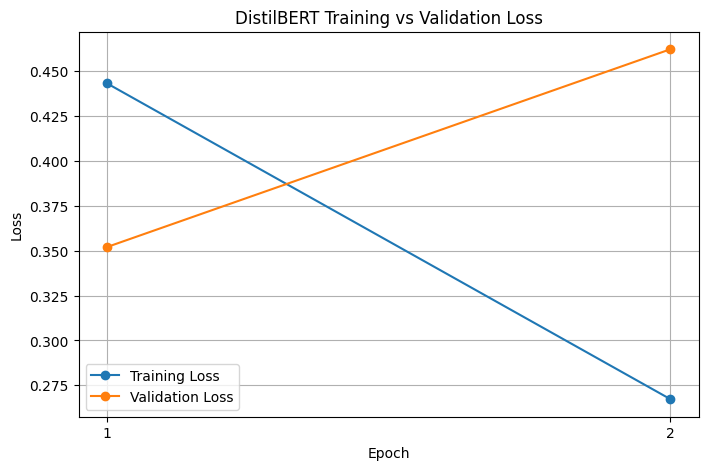

In [10]:
plt.figure(figsize=(8, 5))
plt.plot(history_df["epoch"], history_df["train_loss"], marker="o", label="Training Loss")
plt.plot(history_df["epoch"], history_df["validation_loss"], marker="o", label="Validation Loss")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.title("DistilBERT Training vs Validation Loss")
plt.xticks(history_df["epoch"]); plt.legend(); plt.grid(True); plt.show()

## 10. Final evaluation on held-out test data

DistilBERT Test Accuracy: 0.8554
DistilBERT Test F1-score: 0.8592
              precision    recall  f1-score   support

    Negative       0.87      0.83      0.85      2494
    Positive       0.84      0.88      0.86      2506

    accuracy                           0.86      5000
   macro avg       0.86      0.86      0.86      5000
weighted avg       0.86      0.86      0.86      5000



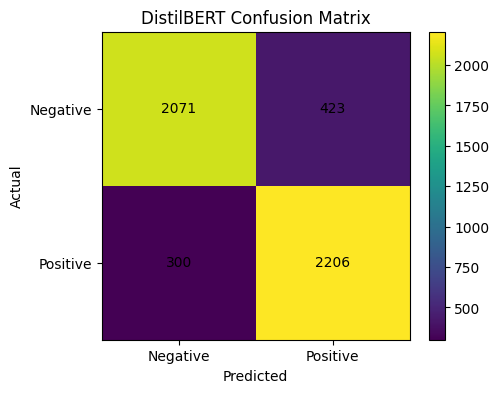

In [11]:
test_metrics = evaluate_model(model, test_loader)
print(f"DistilBERT Test Accuracy: {test_metrics['accuracy']:.4f}")
print(f"DistilBERT Test F1-score: {test_metrics['f1']:.4f}")
print(classification_report(test_metrics["labels"], test_metrics["predictions"],
                            target_names=["Negative", "Positive"]))
cm = confusion_matrix(test_metrics["labels"], test_metrics["predictions"])
plt.figure(figsize=(5, 4)); plt.imshow(cm); plt.title("DistilBERT Confusion Matrix")
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.xticks([0,1], ["Negative","Positive"]); plt.yticks([0,1], ["Negative","Positive"])
for i in range(2):
    for j in range(2): plt.text(j, i, cm[i,j], ha="center", va="center")
plt.colorbar(); plt.show()

## 11. TF-IDF + Logistic Regression baseline
The baseline uses the same selected training and test reviews as DistilBERT.

In [12]:
X_train_text, y_train = train_ds["text"], np.array(train_ds["label"])
X_test_text, y_test = test_ds["text"], np.array(test_ds["label"])

vectorizer = TfidfVectorizer(max_features=30000, ngram_range=(1, 2),
                             stop_words="english", min_df=2)
X_train_tfidf = vectorizer.fit_transform(X_train_text)
X_test_tfidf = vectorizer.transform(X_test_text)

baseline_model = LogisticRegression(max_iter=1000, random_state=SEED)
baseline_model.fit(X_train_tfidf, y_train)
baseline_preds = baseline_model.predict(X_test_tfidf)
baseline_accuracy = accuracy_score(y_test, baseline_preds)
baseline_f1 = f1_score(y_test, baseline_preds)
print(f"TF-IDF + Logistic Regression Accuracy: {baseline_accuracy:.4f}")
print(f"TF-IDF + Logistic Regression F1: {baseline_f1:.4f}")

TF-IDF + Logistic Regression Accuracy: 0.8480
TF-IDF + Logistic Regression F1: 0.8503


## 12. Compare baseline and DistilBERT

,Model,Accuracy,F1-score
0,TF-IDF + Logistic Regression,0.8480,0.850276
1,DistilBERT,0.8554,0.859202


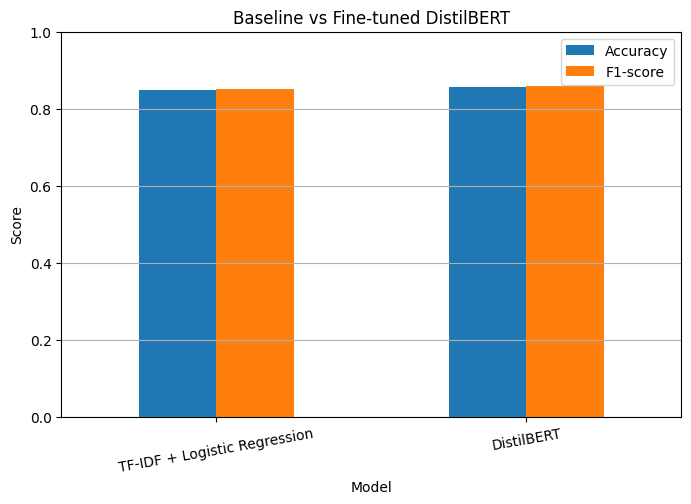

In [13]:
comparison = pd.DataFrame({
    "Model": ["TF-IDF + Logistic Regression", "DistilBERT"],
    "Accuracy": [baseline_accuracy, test_metrics["accuracy"]],
    "F1-score": [baseline_f1, test_metrics["f1"]]
})
display(comparison)
comparison.set_index("Model").plot(kind="bar", figsize=(8,5), ylim=(0,1), rot=10)
plt.title("Baseline vs Fine-tuned DistilBERT"); plt.ylabel("Score")
plt.grid(axis="y"); plt.show()

## 13. Save fine-tuned model and tokenizer

In [14]:
SAVE_DIR = "./distilbert-imdb-sentiment"
os.makedirs(SAVE_DIR, exist_ok=True)
model.save_pretrained(SAVE_DIR)
tokenizer.save_pretrained(SAVE_DIR)
print("Saved model and tokenizer to:", SAVE_DIR)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved model and tokenizer to: ./distilbert-imdb-sentiment


## 14. Reload model and predict sentiment for five new reviews

In [15]:
reloaded_tokenizer = AutoTokenizer.from_pretrained(SAVE_DIR)
reloaded_model = AutoModelForSequenceClassification.from_pretrained(SAVE_DIR).to(DEVICE)
reloaded_model.eval()

def predict_sentiment(texts):
    inputs = reloaded_tokenizer(texts, padding=True, truncation=True,
                                max_length=MAX_LENGTH, return_tensors="pt")
    inputs = {k: v.to(DEVICE) for k, v in inputs.items()}
    with torch.no_grad():
        probs = torch.softmax(reloaded_model(**inputs).logits, dim=-1)
        preds = probs.argmax(dim=-1)
    return pd.DataFrame([
        {"review": text,
         "sentiment": "Positive" if pred == 1 else "Negative",
         "negative_probability": round(float(prob[0]), 4),
         "positive_probability": round(float(prob[1]), 4)}
        for text, pred, prob in zip(texts, preds.cpu().tolist(), probs.cpu().tolist())
    ])

new_reviews = [
    "This movie was wonderful. The acting was excellent and the story kept me interested.",
    "I disliked this film. The plot was boring and the performances were weak.",
    "A beautifully made movie with memorable characters and an emotional ending.",
    "The film was a complete waste of time. I would not recommend it.",
    "The movie had some good moments, but overall it was average."
]
display(predict_sentiment(new_reviews))

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

,review,sentiment,negative_probability,positive_probability
0,This movie was wonderful. The acting was excel...,Positive,0.0076,0.9924
1,I disliked this film. The plot was boring and ...,Negative,0.9930,0.0070
2,A beautifully made movie with memorable charac...,Positive,0.0081,0.9919
3,The film was a complete waste of time. I would...,Negative,0.9931,0.0069
4,"The movie had some good moments, but overall i...",Negative,0.9515,0.0485


## 15. Final project summary

In [16]:
print("Project: ML-13 - BERT Sentiment Analysis")
print("Dataset: IMDb movie reviews")
print("Checkpoint:", MODEL_CHECKPOINT)
print("Device:", DEVICE)
print("Train / Validation / Test:", len(train_ds), "/", len(validation_ds), "/", len(test_ds))
print(f"DistilBERT Accuracy: {test_metrics['accuracy']:.4f}")
print(f"DistilBERT F1: {test_metrics['f1']:.4f}")
print(f"TF-IDF Accuracy: {baseline_accuracy:.4f}")
print(f"TF-IDF F1: {baseline_f1:.4f}")
print("Saved model:", SAVE_DIR)

Project: ML-13 - BERT Sentiment Analysis
Dataset: IMDb movie reviews
Checkpoint: distilbert-base-uncased
Device: cuda
Train / Validation / Test: 5000 / 1000 / 5000
DistilBERT Accuracy: 0.8554
DistilBERT F1: 0.8592
TF-IDF Accuracy: 0.8480
TF-IDF F1: 0.8503
Saved model: ./distilbert-imdb-sentiment


### Reporting notes
- Report the exact split sizes printed by the notebook. The default run uses subsets; it is not the full 50,000-review experiment.
- Use the metrics generated by your own run; do not invent or copy expected scores.
- GPU is strongly recommended. On CPU, keep the subset settings and expect training to take longer.
- The saved model directory is `distilbert-imdb-sentiment`. Download/copy it before a temporary Kaggle session ends.